# 10 - Thử nghiệm Structured Layer Pruning trên Qwen2.5-0.5B-Instruct và so sánh với Quantization

**Mục tiêu:** Kiểm chứng xem việc cắt bớt tầng Transformer (*Structured Layer Pruning* theo phương pháp **ShortGPT / Block Influence**) có giúp tăng tốc và giảm dung lượng hiệu quả hơn hay làm suy giảm Tool Calling so với chỉ dùng Quantization + Imatrix ở [09_qwen25_05b_quant_bench.ipynb](file:///c:/Users/Minor/Downloads/slm/09_qwen25_05b_quant_bench.ipynb).

### Phương pháp thực hiện
1. **Đo độ quan trọng từng tầng (Block Influence - BI):** Cho `Qwen2.5-0.5B-Instruct` (24 layers) chạy qua tập hiệu chuẩn `calib_qwen25_imatrix.txt`. Tầng thứ $i$ có độ biến thiên ẩn thấp nhất ($BI_i = 1 - \mathbb{E}[\cos(h_i, h_{i+1})]$ nhỏ nhất) là tầng đóng góp ít thay đổi nhất.
2. **Cắt cấu trúc ở 2 mức:**
   - **`P2` (22 layers):** Cắt bỏ 2 tầng có điểm BI thấp nhất (~8.3% số tầng).
   - **`P4` (20 layers):** Cắt bỏ 4 tầng có điểm BI thấp nhất (~16.7% số tầng).
   *(Lưu ý: Không cắt tầng đầu `0` và tầng cuối `23` để bảo toàn lớp nhập/xuất đặc trưng.)*
3. **Convert GGUF & Nén 4-bit:** Chuyển 2 bản đã cắt sang GGUF (`F16`), rồi nén sang `Q4_K_M` và `Q4_K_M-imx`.
4. **Đo & So sánh trực tiếp** với kết quả gốc (`Q4_K_M`, `Q4_K_M-imx`, `IQ4_NL-imx`) từ Notebook 09 trên cùng 156 ca Tool Calling và `llama-bench` (`pp128`, `tg64`).

In [1]:
import json
import subprocess
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F_nn
from transformers import AutoModelForCausalLM, AutoTokenizer

import slm_tools as st
import model_catalog as mc
import tool_cases as T

LLAMA_CPP_DIR = Path("./llama.cpp")
MODEL_NAME = "Qwen2.5-0.5B-Instruct"
HF_DIR = mc.CACHE_DIR / "hf" / MODEL_NAME
if not (HF_DIR / "config.json").exists():
    from huggingface_hub import snapshot_download
    snapshot_download(
        repo_id=mc.BASE_MODELS[MODEL_NAME]["hf_repo"],
        local_dir=str(HF_DIR),
        allow_patterns=["*.json", "*.safetensors", "*.model", "*.txt", "*.tiktoken", "*.jinja"],
    )

PRUNE_ROOT = mc.CACHE_DIR / "pruned_qwen25_05b"
PRUNE_ROOT.mkdir(parents=True, exist_ok=True)

CALIB_PATH = mc.CACHE_DIR / "gguf" / "qwen25_05b_quants" / "calib_qwen25_imatrix.txt"
if not CALIB_PATH.exists():
    raise FileNotFoundError(f"Không tìm thấy {CALIB_PATH}. Hãy chạy Bước 1 của Notebook 09 trước.")

BENCH_THREADS = 4
BENCH_NGL = 0
BENCH_REPS = 3

print("HF model:", HF_DIR)
print("Calibration file:", CALIB_PATH, f"({CALIB_PATH.stat().st_size / 1024:.1f} KB)")

c:\Users\Minor\Downloads\slm\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


HF model: model_cache\hf\Qwen2.5-0.5B-Instruct
Calibration file: model_cache\gguf\qwen25_05b_quants\calib_qwen25_imatrix.txt (726.9 KB)


## Bước 1 - Đo điểm Block Influence (BI) của 24 tầng Transformer

Tầng nào có điểm BI thấp nhất là tầng ít làm thay đổi vector ẩn nhất -> ứng viên an toàn nhất để cắt bỏ.

Đang tính Block Influence cho 24 layers...


`torch_dtype` is deprecated! Use `dtype` instead!


Thứ tự tầng ít ảnh hưởng nhất -> nhiều nhất: [18, 13, 12, 10, 11, 21, 19, 9, 17, 22, 14, 20, 15, 16, 8, 7, 6, 5, 2, 3, 4, 1]
Cắt 2 tầng (P2): [13, 18]
Cắt 4 tầng (P4): [10, 12, 13, 18]


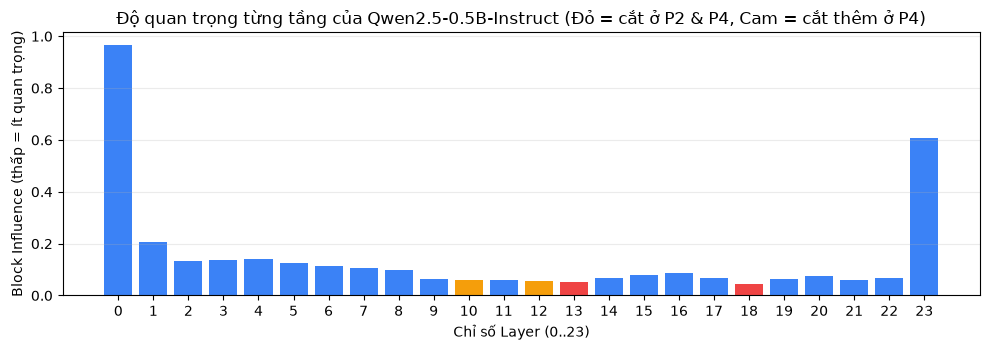

In [2]:
BI_CACHE = PRUNE_ROOT / "block_influence.json"

def compute_block_influence(hf_dir: Path, calib_path: Path, max_chunks: int = 32, seq_len: int = 384) -> list[float]:
    device = "cuda" if torch.cuda.is_available() else "cpu"
    dtype = torch.float16 if device == "cuda" else torch.float32
    tok = AutoTokenizer.from_pretrained(str(hf_dir))
    model = AutoModelForCausalLM.from_pretrained(str(hf_dir), torch_dtype=dtype).to(device)
    model.eval()

    raw_text = calib_path.read_text(encoding="utf-8")
    # Lấy xen kẽ nửa đầu (WikiText) và nửa sau (ChatML Tool Calling) của file hiệu chuẩn
    mid = len(raw_text) // 2
    sample_text = raw_text[:60_000] + "\n" + raw_text[mid:mid + 60_000]
    ids = tok(sample_text, return_tensors="pt", truncation=False)["input_ids"][0]

    n_layers = model.config.num_hidden_layers
    bi_sums = np.zeros(n_layers, dtype=np.float64)
    n_used = 0

    with torch.no_grad():
        for start in range(0, len(ids) - seq_len, seq_len):
            if n_used >= max_chunks:
                break
            chunk = ids[start:start + seq_len].unsqueeze(0).to(device)
            out = model(chunk, output_hidden_states=True)
            hs = out.hidden_states  # tuple dài n_layers + 1
            for i in range(n_layers):
                cos = F_nn.cosine_similarity(hs[i].float(), hs[i + 1].float(), dim=-1)
                bi_sums[i] += float((1.0 - cos).mean().item())
            n_used += 1

    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return [round(float(x / n_used), 5) for x in bi_sums]

if BI_CACHE.exists():
    bi_scores = json.loads(BI_CACHE.read_text(encoding="utf-8"))
else:
    print("Đang tính Block Influence cho 24 layers...")
    bi_scores = compute_block_influence(HF_DIR, CALIB_PATH)
    BI_CACHE.write_text(json.dumps(bi_scores, indent=2), encoding="utf-8")

# Xếp hạng các tầng ở giữa (bỏ tầng 0 và tầng cuối 23)
middle_ranked = sorted(range(1, len(bi_scores) - 1), key=lambda i: bi_scores[i])
DROP_P2 = sorted(middle_ranked[:2])
DROP_P4 = sorted(middle_ranked[:4])
print("Thứ tự tầng ít ảnh hưởng nhất -> nhiều nhất:", middle_ranked)
print("Cắt 2 tầng (P2):", DROP_P2)
print("Cắt 4 tầng (P4):", DROP_P4)

fig, ax = plt.subplots(figsize=(10, 3.6))
colors = ["#ef4444" if i in DROP_P2 else ("#f59e0b" if i in DROP_P4 else "#3b82f6") for i in range(len(bi_scores))]
ax.bar(range(len(bi_scores)), bi_scores, color=colors)
ax.set_xticks(range(len(bi_scores)))
ax.set_xlabel("Chỉ số Layer (0..23)")
ax.set_ylabel("Block Influence (thấp = ít quan trọng)")
ax.set_title("Độ quan trọng từng tầng của Qwen2.5-0.5B-Instruct (Đỏ = cắt ở P2 & P4, Cam = cắt thêm ở P4)")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## Bước 2 - Cắt tầng, chuyển sang GGUF (F16) và nén 4-bit (`Q4_K_M`, `Q4_K_M-imx`)

In [3]:
def build_pruned_hf_model(src_hf: Path, drop_layers: list[int], out_hf: Path):
    if (out_hf / "config.json").exists():
        print(f"[đã có HF] {out_hf.name}")
        return
    print(f"[đang cắt tầng {drop_layers}] -> {out_hf.name}")
    tok = AutoTokenizer.from_pretrained(str(src_hf))
    model = AutoModelForCausalLM.from_pretrained(str(src_hf), torch_dtype=torch.float16)

    keep = [layer for idx, layer in enumerate(model.model.layers) if idx not in set(drop_layers)]
    model.model.layers = torch.nn.ModuleList(keep)
    model.config.num_hidden_layers = len(keep)
    for new_idx, layer in enumerate(model.model.layers):
        if hasattr(layer, "self_attn") and hasattr(layer.self_attn, "layer_idx"):
            layer.self_attn.layer_idx = new_idx

    out_hf.mkdir(parents=True, exist_ok=True)
    model.save_pretrained(str(out_hf), safe_serialization=True)
    tok.save_pretrained(str(out_hf))
    del model

convert_py = LLAMA_CPP_DIR / "convert_hf_to_gguf.py"
imatrix_bin = mc.find_llama_bin("llama-imatrix", LLAMA_CPP_DIR)
quant_bin = mc.find_llama_bin("llama-quantize", LLAMA_CPP_DIR)

PRUNE_SPECS = [
    {"tag": "P2", "drop": DROP_P2, "layers": 22},
    {"tag": "P4", "drop": DROP_P4, "layers": 20},
]

PRUNED_VARIANTS = []
for spec in PRUNE_SPECS:
    tag = spec["tag"]
    hf_out = PRUNE_ROOT / f"{MODEL_NAME}-{tag}-hf"
    build_pruned_hf_model(HF_DIR, spec["drop"], hf_out)

    f16_gguf = PRUNE_ROOT / f"{MODEL_NAME}-{tag}.F16.gguf"
    if not f16_gguf.exists():
        mc._run([sys.executable, convert_py, hf_out, "--outfile", f16_gguf, "--outtype", "f16"])
    else:
        print(f"[đã có F16] {f16_gguf.name}")

    imx_gguf = PRUNE_ROOT / f"{MODEL_NAME}-{tag}.imatrix.gguf"
    if not imx_gguf.exists():
        mc._run([
            imatrix_bin, "-m", str(f16_gguf), "-f", str(CALIB_PATH), "-o", str(imx_gguf),
            "--process-output", "--parse-special", "-c", "512", "--chunks", "80", "-ngl", str(st.GPU_LAYERS),
        ])
    else:
        print(f"[đã có imatrix] {imx_gguf.name}")

    for use_imx in (False, True):
        qid = f"{tag}-Q4_K_M-imx" if use_imx else f"{tag}-Q4_K_M"
        q_gguf = PRUNE_ROOT / f"{MODEL_NAME}.{qid}.gguf"
        if not q_gguf.exists():
            cmd = [quant_bin]
            if use_imx:
                cmd += ["--imatrix", str(imx_gguf)]
            cmd += [str(f16_gguf), str(q_gguf), "Q4_K_M"]
            mc._run(cmd)
        else:
            print(f"[đã có GGUF] {q_gguf.name}")
        PRUNED_VARIANTS.append({
            "quant_id": qid,
            "tag": tag,
            "layers": spec["layers"],
            "use_imx": use_imx,
            "file": q_gguf,
        })

[đang cắt tầng [13, 18]] -> Qwen2.5-0.5B-Instruct-P2-hf
[run] c:\Users\Minor\Downloads\slm\.venv\Scripts\python.exe llama.cpp\convert_hf_to_gguf.py model_cache\pruned_qwen25_05b\Qwen2.5-0.5B-Instruct-P2-hf --outfile model_cache\pruned_qwen25_05b\Qwen2.5-0.5B-Instruct-P2.F16.gguf --outtype f16
[run] llama.cpp\build\bin\Release\llama-imatrix.exe -m model_cache\pruned_qwen25_05b\Qwen2.5-0.5B-Instruct-P2.F16.gguf -f model_cache\gguf\qwen25_05b_quants\calib_qwen25_imatrix.txt -o model_cache\pruned_qwen25_05b\Qwen2.5-0.5B-Instruct-P2.imatrix.gguf --process-output --parse-special -c 512 --chunks 80 -ngl 99
[run] llama.cpp\build\bin\Release\llama-quantize.exe model_cache\pruned_qwen25_05b\Qwen2.5-0.5B-Instruct-P2.F16.gguf model_cache\pruned_qwen25_05b\Qwen2.5-0.5B-Instruct.P2-Q4_K_M.gguf Q4_K_M
[run] llama.cpp\build\bin\Release\llama-quantize.exe --imatrix model_cache\pruned_qwen25_05b\Qwen2.5-0.5B-Instruct-P2.imatrix.gguf model_cache\pruned_qwen25_05b\Qwen2.5-0.5B-Instruct-P2.F16.gguf model_c

## Bước 3 - Đo tốc độ (`pp128`, `tg64`) và Tool Calling cho các bản đã cắt tầng

In [4]:
bench_bin = mc.find_llama_bin("llama-bench", LLAMA_CPP_DIR)
CASES = T.make_cases()
PRUNE_RESULT_FILE = st.RESULTS_DIR / "qwen25_05b_pruned.json"
RAW_DIR = st.RESULTS_DIR / "raw_qwen25_pruned"
RAW_DIR.mkdir(parents=True, exist_ok=True)

def measure_speed_llama_bench(gguf_path: Path, threads: int = BENCH_THREADS, ngl: int = BENCH_NGL, reps: int = BENCH_REPS) -> dict:
    cmd = [
        str(bench_bin), "-m", str(gguf_path), "-p", "128", "-n", "64",
        "-r", str(reps), "-t", str(threads), "-ngl", str(ngl), "-o", "json",
    ]
    proc = subprocess.run(cmd, capture_output=True, text=True, encoding="utf-8", errors="replace", check=True)
    stdout = proc.stdout.strip()
    data = json.loads(stdout[stdout.find("["):])
    pp128_tps, tg64_tps = 0.0, 0.0
    for entry in data:
        if entry.get("n_prompt", 0) > 0 and entry.get("n_gen", 0) == 0:
            pp128_tps = float(entry["avg_ts"])
        elif entry.get("n_gen", 0) > 0 and entry.get("n_prompt", 0) == 0:
            tg64_tps = float(entry["avg_ts"])
    return {"pp128_tps": round(pp128_tps, 2), "tg64_tps": round(tg64_tps, 2)}

def measure_native_tool_calling(cfg: dict) -> dict:
    rows = []
    tool_names = T.TOOL_SETS[11]
    with st.server(cfg) as srv:
        for c in CASES:
            msgs, tools = T.native_request(c, tool_names)
            out = srv.ask(msgs, tools=tools, max_tokens=150)
            sc = T.score_native(c, out)
            rows.append({
                "id": c["id"], "want_tool": c["tool"], "noisy": c["noisy"],
                "called": bool(out.get("tool_calls")),
                "tool_calls": out.get("tool_calls", []), "text": out.get("text", ""), **sc,
            })

    with (RAW_DIR / f"{cfg['quant_id']}.jsonl").open("w", encoding="utf-8") as f:
        for r in rows:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")

    df = pd.DataFrame(rows)
    in_scope = df[df["want_tool"].notna()]
    oos = df[df["want_tool"].isna()]
    intent_correct = ((in_scope["called"] == True).sum() + (oos["called"] == False).sum()) / len(df)
    return {
        "overall_acc": round(float(df["ok"].mean()), 4),
        "tool_select_acc": round(float(in_scope["ok"].mean()), 4),
        "tool_name_acc": round(float(in_scope["tool_ok"].mean()), 4),
        "intent_acc": round(float(intent_correct), 4),
        "over_calling": round(float(oos["over_trigger"].mean()), 4),
    }

saved = json.loads(PRUNE_RESULT_FILE.read_text(encoding="utf-8")) if PRUNE_RESULT_FILE.exists() else []
done_map = {r["quant_id"]: r for r in saved}

for pv in PRUNED_VARIANTS:
    qid = pv["quant_id"]
    if qid in done_map:
        print(f"[đã đo] {qid} -> pp128={done_map[qid]['pp128_tps']} t/s, tg64={done_map[qid]['tg64_tps']} t/s, tool_select={done_map[qid]['tool_select_acc']*100:.1f}%")
        continue
    gguf_path = pv["file"]
    size_mib = round(gguf_path.stat().st_size / (1024 ** 2), 1)
    print(f"\n=== Đang đánh giá {MODEL_NAME} ({qid} | {pv['layers']} layers | {size_mib} MiB) ===")
    t0 = time.perf_counter()
    speed_metrics = measure_speed_llama_bench(gguf_path)
    print(f"  -> Tốc độ: pp128 = {speed_metrics['pp128_tps']:.2f} tok/s | tg64 = {speed_metrics['tg64_tps']:.2f} tok/s")
    cfg = {"id": f"{MODEL_NAME}__{qid}", "name": MODEL_NAME, "quant": "Q4_K_M", "quant_id": qid, "params_b": 0.5, "file": gguf_path}
    tool_metrics = measure_native_tool_calling(cfg)
    print(
        f"  -> Tool Calling: Intent = {tool_metrics['intent_acc']*100:.1f}% | "
        f"Gọi thừa = {tool_metrics['over_calling']*100:.1f}% | "
        f"Chọn đúng tool = {tool_metrics['tool_select_acc']*100:.1f}% | "
        f"Tổng hợp = {tool_metrics['overall_acc']*100:.1f}% ({time.perf_counter() - t0:.0f}s)"
    )
    done_map[qid] = {"model": MODEL_NAME, "quant_id": qid, "layers": pv["layers"], "size_mib": size_mib, **speed_metrics, **tool_metrics}
    PRUNE_RESULT_FILE.write_text(json.dumps(list(done_map.values()), indent=2, ensure_ascii=False), encoding="utf-8")


=== Đang đánh giá Qwen2.5-0.5B-Instruct (P2-Q4_K_M | 22 layers | 358.6 MiB) ===
  -> Tốc độ: pp128 = 541.44 tok/s | tg64 = 125.17 tok/s
  -> Tool Calling: Intent = 24.4% | Gọi thừa = 0.0% | Chọn đúng tool = 6.8% | Tổng hợp = 21.1% (365s)

=== Đang đánh giá Qwen2.5-0.5B-Instruct (P2-Q4_K_M-imx | 22 layers | 358.6 MiB) ===
  -> Tốc độ: pp128 = 526.90 tok/s | tg64 = 130.39 tok/s
  -> Tool Calling: Intent = 20.5% | Gọi thừa = 0.0% | Chọn đúng tool = 3.0% | Tổng hợp = 17.9% (356s)

=== Đang đánh giá Qwen2.5-0.5B-Instruct (P4-Q4_K_M | 20 layers | 340.1 MiB) ===
  -> Tốc độ: pp128 = 565.74 tok/s | tg64 = 136.16 tok/s
  -> Tool Calling: Intent = 15.4% | Gọi thừa = 0.0% | Chọn đúng tool = 0.0% | Tổng hợp = 15.4% (410s)

=== Đang đánh giá Qwen2.5-0.5B-Instruct (P4-Q4_K_M-imx | 20 layers | 340.1 MiB) ===
  -> Tốc độ: pp128 = 597.62 tok/s | tg64 = 139.14 tok/s
  -> Tool Calling: Intent = 15.4% | Gọi thừa = 0.0% | Chọn đúng tool = 0.0% | Tổng hợp = 15.4% (377s)


## Bước 4 - So sánh trực tiếp: Pruning + Quant vs Chỉ dùng Quant (từ Notebook 09)

,Biến thể,Số Layer,File (MiB),pp128 (tok/s),tg64 (tok/s),Intent,Gọi thừa,Chọn đúng tool,Tổng hợp (156 ca)
0,Q4_K_M,24,379.4,328.13,75.96,57.0%,41.7%,42.4%,44.9%
1,Q4_K_M-imx,24,379.4,287.47,76.36,63.5%,12.5%,46.2%,52.6%
2,IQ4_NL-imx,24,336.3,546.91,153.04,55.1%,0.0%,35.6%,45.5%
3,Q4_K_M-o4,24,314.5,496.45,124.10,56.4%,29.2%,34.1%,39.7%
4,P2-Q4_K_M,22,358.6,541.44,125.17,24.4%,0.0%,6.8%,21.1%
5,P2-Q4_K_M-imx,22,358.6,526.90,130.39,20.5%,0.0%,3.0%,17.9%
6,P4-Q4_K_M,20,340.1,565.74,136.16,15.4%,0.0%,0.0%,15.4%
7,P4-Q4_K_M-imx,20,340.1,597.62,139.14,15.4%,0.0%,0.0%,15.4%


Đã lưu biểu đồ tại: charts\10_qwen25_05b_pruning_vs_quant.png


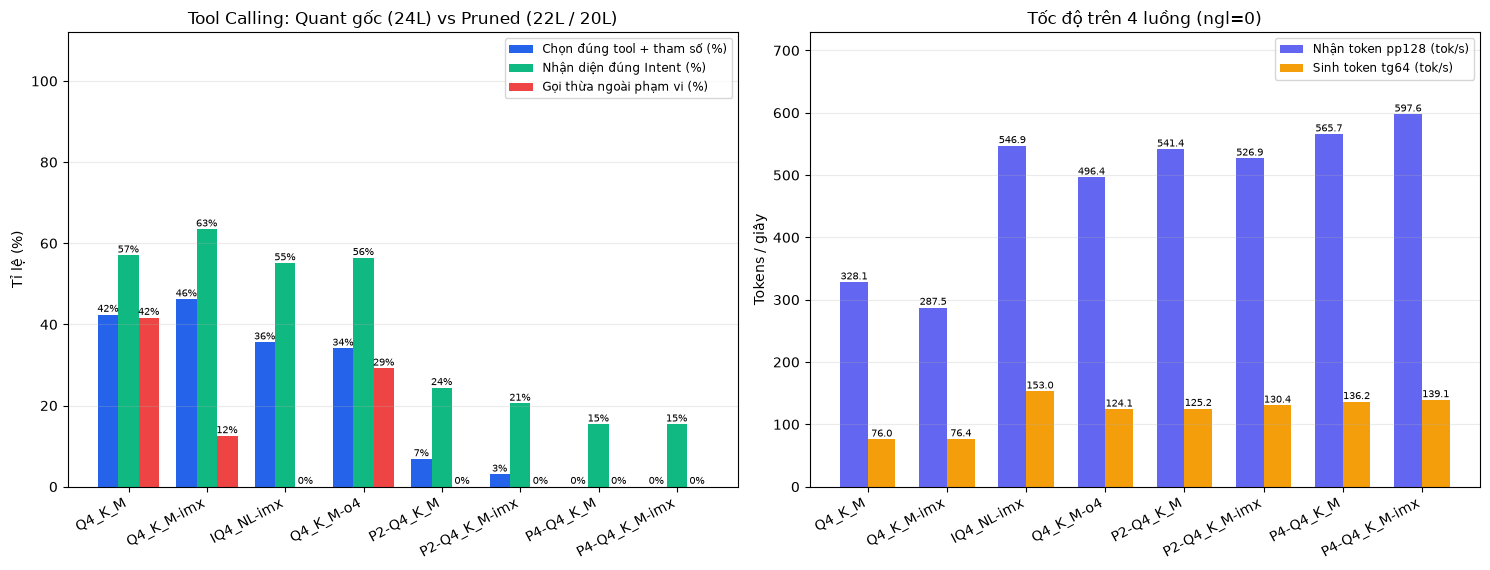

In [5]:
base_file = st.RESULTS_DIR / "qwen25_05b_quants.json"
base_rows = json.loads(base_file.read_text(encoding="utf-8")) if base_file.exists() else []
keep_base = [r for r in base_rows if r["quant_id"] in ("Q4_K_M", "Q4_K_M-imx", "IQ4_NL-imx", "Q4_K_M-o4")]
for r in keep_base:
    r["layers"] = 24

prune_rows = json.loads(PRUNE_RESULT_FILE.read_text(encoding="utf-8"))
df_cmp = pd.DataFrame(keep_base + prune_rows)

disp = pd.DataFrame({
    "Biến thể": df_cmp["quant_id"],
    "Số Layer": df_cmp["layers"],
    "File (MiB)": df_cmp["size_mib"].map(lambda v: f"{v:.1f}"),
    "pp128 (tok/s)": df_cmp["pp128_tps"].map(lambda v: f"{v:.2f}"),
    "tg64 (tok/s)": df_cmp["tg64_tps"].map(lambda v: f"{v:.2f}"),
    "Intent": df_cmp["intent_acc"].map(lambda v: f"{v*100:.1f}%"),
    "Gọi thừa": df_cmp["over_calling"].map(lambda v: f"{v*100:.1f}%"),
    "Chọn đúng tool": df_cmp["tool_select_acc"].map(lambda v: f"{v*100:.1f}%"),
    "Tổng hợp (156 ca)": df_cmp["overall_acc"].map(lambda v: f"{v*100:.1f}%"),
})
display(disp)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
x = np.arange(len(df_cmp))
labels = df_cmp["quant_id"].tolist()

w = 0.26
ax1 = axes[0]
b1 = ax1.bar(x - w, df_cmp["tool_select_acc"] * 100, w, label="Chọn đúng tool + tham số (%)", color="#2563eb")
b2 = ax1.bar(x,     df_cmp["intent_acc"] * 100,      w, label="Nhận diện đúng Intent (%)",    color="#10b981")
b3 = ax1.bar(x + w, df_cmp["over_calling"] * 100,    w, label="Gọi thừa ngoài phạm vi (%)",   color="#ef4444")
ax1.set_xticks(x)
ax1.set_xticklabels(labels, rotation=28, ha="right")
ax1.set_ylim(0, 112)
ax1.set_ylabel("Tỉ lệ (%)")
ax1.set_title("Tool Calling: Quant gốc (24L) vs Pruned (22L / 20L)")
ax1.legend(loc="upper right", fontsize=8.5)
ax1.grid(axis="y", alpha=0.25)
for bars in (b1, b2, b3):
    for bar in bars:
        h = bar.get_height()
        ax1.annotate(f"{h:.0f}%", (bar.get_x() + bar.get_width() / 2, h),
                     xytext=(0, 2), textcoords="offset points", ha="center", fontsize=7.5)

ax2 = axes[1]
w2 = 0.35
s1 = ax2.bar(x - w2/2, df_cmp["pp128_tps"], w2, label="Nhận token pp128 (tok/s)", color="#6366f1")
s2 = ax2.bar(x + w2/2, df_cmp["tg64_tps"],  w2, label="Sinh token tg64 (tok/s)",  color="#f59e0b")
ax2.set_xticks(x)
ax2.set_xticklabels(labels, rotation=28, ha="right")
ax2.set_ylim(0, max(df_cmp["pp128_tps"].max() * 1.22, 650))
ax2.set_ylabel("Tokens / giây")
ax2.set_title(f"Tốc độ trên {BENCH_THREADS} luồng (ngl={BENCH_NGL})")
ax2.legend(loc="upper right", fontsize=8.5)
ax2.grid(axis="y", alpha=0.25)
for bars in (s1, s2):
    for bar in bars:
        h = bar.get_height()
        ax2.annotate(f"{h:.1f}", (bar.get_x() + bar.get_width() / 2, h),
                     xytext=(0, 2), textcoords="offset points", ha="center", fontsize=7.5)

fig.tight_layout()
st.CHARTS_DIR.mkdir(exist_ok=True)
chart_path = st.CHARTS_DIR / "10_qwen25_05b_pruning_vs_quant.png"
fig.savefig(chart_path, dpi=180, bbox_inches="tight")
print("Đã lưu biểu đồ tại:", chart_path)
plt.show()